# 02 · Topic categorisation — a hybrid pipeline

**Goal:** categorise 100 calls by topic so support, sales, product and engineering leaders can each find "their" calls.

**Why hybrid.** Each method alone fails in a way this data makes visible:

| Method | What it's good at | Where it breaks on this data |
|---|---|---|
| **Rules** | Call type, product mentions — deterministic, free, explainable | Can't read meaning: the title rule found 15 incident calls, the real number is 37 |
| **Clustering** | Discovering themes nobody named in advance | One label per call; weak separation (silhouette ≤ 0.23); unstable across seeds (ARI 0.55); splits one story into 5 clusters |
| **LLM** | Reading meaning, multi-label, quoting evidence | Invents categories inconsistently (17 parent names for 24 clusters); over-labels (fills the 4-label cap 84% of the time) |

So each method does the job it's best at:

```
Raw transcripts
  → Clean + speaker normalise + PII redact                       (rules)
  → Call type                                                     (rules, LLM second opinion)
  → Per-call structured extraction, evidence quotes               (LLM → Pydantic schema)
  → Theme discovery over extracted issue statements               (embeddings + UMAP + HDBSCAN)
  → Name clusters                                                 (LLM)  →  curate a fixed 2-level taxonomy (human)
  → Classify every call: multi-label + confidence + evidence      (LLM, constrained to the taxonomy)
  → Validate: quote grounding (automatic) + 25 hand-labelled calls (human)
```

Every LLM response is cached in `cache/llm/`, so this notebook re-runs offline at no cost. Model: `claude-opus-5-5`.

In [1]:
import json, warnings
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
from transcript_intel import load_tables, llm, topics
from transcript_intel import cluster as cl
from transcript_intel.preprocess import redact, call_documents, render_transcript
from transcript_intel.embed import embed_documents
from transcript_intel.validation import LABEL_DIR, load_labels

pd.set_option("display.max_colwidth", 110); pd.set_option("display.width", 200)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
TYPE_ORDER = ["support", "external", "internal"]
REPORTS = Path.cwd().parent / "reports"; REPORTS.mkdir(exist_ok=True)

calls, sentences, moments = load_tables()
red = redact(sentences)

## 1. Clean, normalise speakers, redact PII

From the audit: IDs are masked, customer contacts become "Customer 1/2…" per call, staff and company names stay.
Lines are tagged `[AEGIS]` / `[CUSTOMER]`. Greeting/sign-off boilerplate is flagged so clustering can ignore it.

In [2]:
mid = calls.loc[calls.title.str.startswith("URGENT: Blackridge"), "meeting_id"].iloc[0]
print(render_transcript(red[red.meeting_id == mid].head(4)))

[AEGIS] Marcus Williams: Thank you for calling Aegis Cloud Security support, this is Marcus Williams, how can I help you today?
[CUSTOMER] Customer 1: Marcus, hi, this is Customer 1 from Blackridge Investments and I need you to understand right now that this is a critical, critical situation — we have zero threat visibility, zero, and it has been that way for over three hours.
[AEGIS] Marcus Williams: Okay, Customer 1, I hear you, I'm pulling up your account right now — can you give me your account ID or the email on file so I can get in faster?
[CUSTOMER] Customer 1: It's Blackridge Investments, B-L-A-C-K-R-I-D-G-E, account number [ID], and I also already submitted a ticket, ticket number... uh, I have it here somewhere — it's [ID].


In [3]:
leaks_ids = red.clean_text.str.contains(r"\b[A-Z]{2,4}-\d{4,}").sum()
leaks_names = sum(g.clean_text.str.contains(rf"\b{n.split()[0]}\b").sum()
                  for mid, g in red.groupby("meeting_id")
                  for n in set(g.loc[g.side == "customer", "speaker"]) if not n.startswith("Dr."))
print(f"ID leaks: {leaks_ids} · customer-name leaks: {leaks_names} · boilerplate lines flagged: {red.is_boilerplate.sum()}")

ID leaks: 0 · customer-name leaks: 0 · boilerplate lines flagged: 279


> **Decision:** only redacted text is sent to the API. Leak checks are also unit tests (`tests/test_preprocess.py`).

## 2. Call type — rules first, LLM as a second opinion

There is no call-type label in the data (audit §3). Rules derive it from attendee domains + title patterns.
Instead of "relabelling where the source is wrong", I asked Claude to classify every call from its *content*
and measured disagreement.

In [4]:
ct = topics.check_call_types(calls, red)
print(f"Rule vs LLM agreement: {ct.agrees.sum()}/{len(ct)} · min LLM confidence {ct.confidence.min():.2f}")
pd.crosstab(ct.call_type, ct.llm_call_type)

Rule vs LLM agreement: 100/100 · min LLM confidence 0.80


llm_call_type,external,internal,support
call_type,,,
external,40,0,0
internal,0,30,0
support,0,0,30


In [5]:
# Where they *do* differ: is the call substantially about an incident?
print(pd.crosstab(ct.incident_flag, ct.llm_incident, rownames=["title keyword rule"], colnames=["LLM: incident-related"]))
missed = ct[ct.llm_incident & ~ct.incident_flag].merge(calls[["meeting_id", "start"]])
missed.assign(date=missed.start.dt.date)[["date", "title", "call_type"]].sort_values("date")

LLM: incident-related  False  True 
title keyword rule                 
False                     61     24
True                       2     13


,date,title,call_type
21,2026-02-03,Support Case #3286 - Vanta Health Systems API Integration Error,support
16,2026-02-14,Support Case #6635 - Nova Retail Group SSO Login Failures,support
17,2026-02-18,Support Case #1750 - Vanta Health Systems SIEM Connector Issue,support
14,2026-02-24,Support Case #3677 - Coastal Living Co MFA Token Failures,support
11,2026-03-11,Support Case #3266 - Trailhead Marketplace Detect Alerts Not Firing,support
13,2026-03-13,Support Case #6573 - Ridgeline Logistics Detect Data Gaps,support
1,2026-03-14,Aegis / Meridian Capital - Service Reliability Discussion,external
2,2026-03-14,Support Case #5889 - Ridgeline Logistics Detect Latency Issues,support
22,2026-03-16,Support Case #3103 - Silverline Brands Detect False Positives After Patch,support
7,2026-03-18,Support Case #7537 - Forge Industries Detect Recovery Confirmation,support


> **Decision — call type:** rules and LLM agree on **100/100** calls with confidence ≥ 0.8, so the rule-based label stands —
> it's free, deterministic and unit-tested. The LLM check is what lets us *say* that with evidence.
>
> **Decision — incident flag:** the title rule catches **15** incident-related calls; Claude finds **37**. The 24 it adds
> are real: renewal calls dominated by the March outage (Nova Retail, Steelpoint, Ironclad, Cobalt, Ironworks, Brightpath)
> and April support cases caused by the *remediation* (LogVault timeouts from the new circuit breaker, backup windows,
> policy-sync delays). Use the LLM flag for incident analysis. *Insight preview: the outage's reach is ~2.5× what titles show.*

## 3. Baseline: cluster whole calls

Before using an LLM for topics, how far does pure clustering get? Two representations of each call:
TF-IDF (+ LSA) and sentence embeddings (`all-mpnet-base-v2`, chunk-averaged because the model reads only 384 tokens).
Speaker, customer and company names are removed so clusters can't form around *who* is talking.

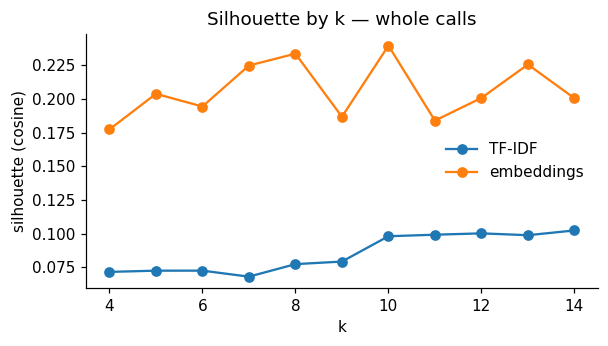

In [6]:
docs = call_documents(red).reindex(calls.meeting_id)
names = set(sentences.speaker.str.split().str[0]) | set(sentences.speaker.str.split().str[-1]) | {a.split(".")[0] for a in calls.account.dropna()}
Z, vec, X = cl.tfidf_lsa(docs.values, extra_stop=names)
E_calls = embed_documents(docs.values)

sweep = cl.sweep_kmeans(Z).rename(columns={"silhouette": "TF-IDF"}).merge(
        cl.sweep_kmeans(E_calls).rename(columns={"silhouette": "embeddings"}))
ax = sweep.set_index("k").plot(marker="o", figsize=(6, 3), title="Silhouette by k — whole calls")
ax.set_ylabel("silhouette (cosine)"); ax.legend(frameon=False); plt.show()

In [7]:
k = 8
lab = cl.kmeans(E_calls, k)
tt = cl.top_terms(X, vec, lab)
pd.DataFrame([{"cluster": c, "calls": int((lab == c).sum()),
               "by type": dict(calls[lab == c].call_type.value_counts()),
               "top terms": ", ".join(tt[c][:6]),
               "example titles": " | ".join(calls[lab == c].title.str[:38].head(2))} for c in range(k)])

,cluster,calls,by type,top terms,example titles
0,0,14,"{'internal': 13, 'external': 1}","sprint, qa, node, march, pipeline, test",Weekly Engineering Standup | Identity Team - Sprint Retro
1,1,8,"{'external': 5, 'internal': 2, 'support': 1}","mfa, identity, sso, okta, session, saml",Identity Team - Q2 Roadmap | Product Sync - Identity Roadmap
2,2,21,"{'support': 11, 'internal': 7, 'external': 3}","monitoring, failure, pipeline, processing, threat, incident",Detect Outage - Remediation Plan Revie | Aegis / Meridian Capital - Service Rel
3,3,4,{'support': 4},"billing, invoice, overage, charge, limit, line item",Support Case #9279 - Summit Trust Bill | Support Case #8179 - Clearwater Medica
4,4,18,"{'external': 17, 'internal': 1}","renewal, pricing, proposal, year, contract, soc",Aegis / Cobalt Software - Q2 Planning | Aegis / Atlas Precision - Contract Dis
5,5,20,"{'external': 10, 'internal': 6, 'support': 4}","control, evidence, soc, framework, audit, controls",Aegis / Redwood Clinical - ISO 27001 P | SOC 2 Audit Preparation - Internal
6,6,9,{'support': 9},"console, authentication, users, seeing, identity, jobs",Support Case #6977 - Brightpath Commer | Support Case #2638 - Pineridge Systems
7,7,6,"{'external': 4, 'support': 1, 'internal': 1}","restore, cloudprime, backup, recovery, protect, onboarding",Support Case #1514 - Meridian Capital | Aegis / Coastal Living Co - Protect Mo


In [8]:
print("Agreement with call type:", {k_: round(v, 2) for k_, v in cl.alignment(lab, calls.call_type.values).items()})
summit = calls.title.str.contains("Summit Trust - Platform Concerns")
print("Example of the one-label limit — Summit Trust 'Platform Concerns' lands in cluster", lab[summit.values][0],
      "→", tt[lab[summit.values][0]][:4])

Agreement with call type: {'ARI': 0.18, 'purity': np.float64(0.73)}
Example of the one-label limit — Summit Trust 'Platform Concerns' lands in cluster 1 → ['mfa', 'identity', 'sso', 'okta']


> **Finding:** clustering finds real domains — billing, renewals, compliance, identity, backup, the outage, internal engineering —
> but separation is weak (silhouette ≤ 0.10 for TF-IDF, ≤ 0.23 for embeddings, flat across *k*) and it's partly just
> rediscovering call type (purity ≈ 0.7). Its hard limit is **one label per call**: Summit Trust's call is about the outage,
> renewal risk *and* a competitor, but can only sit in one cluster.
>
> **Decision:** don't cluster calls. Break each call into its individual issues first (LLM), then cluster the issues.

## 4. Per-call structured extraction (LLM → Pydantic)

Each redacted transcript goes to Claude with a strict schema (`schemas.CallExtraction`): 3–6 generic issue statements,
each with product, severity, who raised it and a **verbatim evidence quote**; plus feature requests, competitors,
churn risk and resolution — reused for the insights in notebook 04.
Grounding check: every quote is searched for in the transcript (case/punctuation-insensitive).

In [9]:
calls_x, issues = topics.extract(calls, red)
print(f"{len(issues)} issues from {issues.meeting_id.nunique()} calls · {len(issues)/100:.1f} per call · "
      f"refusals {calls_x.refused.sum()} · quotes grounded {issues.grounded.mean():.0%}")
issues.loc[issues.title.str.contains("Summit Trust - Platform"), ["statement", "product", "severity", "raised_by"]]

529 issues from 100 calls · 5.3 per call · refusals 0 · quotes grounded 100%


,statement,product,severity,raised_by
235,"MFA is inconsistently enforced, allowing some users to access sensitive applications without being prompted",Identity,high,customer
236,"SSO sessions time out well before the configured inactivity limit, interrupting active user workflows",Identity,high,customer
237,"Support tickets for critical issues receive slow, generic responses and repeatedly require escalation thro...",None,high,customer
238,Threat detection outage caused by a single point of failure in event ingestion left the customer without v...,Detect,high,customer
239,Identity and access management capabilities are perceived as not enterprise-grade for a regulated organisa...,Identity,medium,customer
240,"Upcoming compliance release with on-demand multi-framework reporting is of interest, particularly for PCI DSS",Comply,low,aegis


> **Finding:** 529 issues, **100% of evidence quotes found verbatim** in the source — no hallucinated evidence. The Summit Trust call that clustering forced into one bucket now yields separate issues.

## 5. Theme discovery: embeddings + UMAP + HDBSCAN over issue statements

The BERTopic recipe without the dependency: embed each statement, reduce with UMAP, density-cluster with HDBSCAN,
describe clusters with class-based TF-IDF. Parameters were chosen to avoid both a 135-statement catch-all cluster
and dozens of tiny clusters (sweep in the next cell).

In [10]:
import umap
from sklearn.cluster import HDBSCAN
from sklearn.metrics import adjusted_rand_score
from transcript_intel.embed import embed

E_iss = embed(issues.statement.tolist())
rows = []
for nn in (10, 15):
    for mcs in (5, 8, 12):
        lab_ = cl.umap_hdbscan(E_iss, n_neighbors=nn, min_cluster_size=mcs, min_samples=2)[0]
        sizes = pd.Series(lab_[lab_ >= 0]).value_counts()
        rows.append({"n_neighbors": nn, "min_cluster_size": mcs, "clusters": len(sizes),
                     "noise": f"{(lab_ == -1).mean():.0%}", "largest": sizes.max()})
pd.DataFrame(rows)

,n_neighbors,min_cluster_size,clusters,noise,largest
0,10,5,40,10%,40
1,10,8,24,7%,46
2,10,12,19,5%,135
3,15,5,34,10%,81
4,15,8,19,9%,81
5,15,12,14,2%,135


In [11]:
# Stability: same parameters, different UMAP seeds
runs = [HDBSCAN(min_cluster_size=8, min_samples=2).fit_predict(
            umap.UMAP(n_neighbors=10, n_components=5, metric="cosine", min_dist=0.0, random_state=s).fit_transform(E_iss))
        for s in (1, 2, 3, 42)]
aris = [adjusted_rand_score(a, b) for i, a in enumerate(runs) for b in runs[i + 1:]]
print(f"Cross-seed ARI: mean {np.mean(aris):.2f}, min {min(aris):.2f} · clusters per seed: {[len(set(r) - {-1}) for r in runs]}")

Cross-seed ARI: mean 0.55, min 0.43 · clusters per seed: [25, 19, 23, 24]


In [12]:
iss, terms, _ = topics.discover_themes(issues, min_cluster_size=8, min_samples=2, n_neighbors=10)
named = topics.name_clusters(iss, terms)
print(f"{len(named)} clusters · noise {(iss.cluster == -1).sum()} statements ({(iss.cluster == -1).mean():.0%})")
named.sort_values("size", ascending=False)[["cluster", "size", "n_calls", "name", "suggested_parent", "coherence", "terms"]]

24 clusters · noise 39 statements (7%)


,cluster,size,n_calls,name,suggested_parent,coherence,terms
11,11,46,28,Manual Compliance Audit Preparation,Compliance Reporting,high,"compliance, evidence, audit, manual, preparation, manual compliance"
13,13,40,30,Outage fallout and competitive risk,Platform Reliability,medium,"outage, reliability, deals, root, root cause, competitors"
6,6,38,17,Backup Job Performance and Restore Gaps,Backup and Recovery,medium,"backup, restore, file, snapshot, backup jobs, job"
15,15,34,19,Identity SSO and QA Testing Gaps,Identity & Authentication,medium,"provider, sso, test, connector, qa, certificate"
22,22,30,23,Ingestion Pipeline Single Point Failure,Platform Reliability,high,"ingestion, event ingestion, event, failure, point failure, single point"
9,9,28,24,Comply module adoption and framework needs,Compliance Reporting,medium,"compliance, reporting, compliance reporting, module, readiness, demand"
23,23,22,21,Detect Ingestion Pipeline Outage,Platform Reliability,high,"event, threat detection, detection, pipeline, ingestion, event ingestion"
16,16,22,14,MFA and Access Management Gaps,Identity,medium,"mfa, access, access management, identity, role, permissions"
10,10,21,15,Comply Report and Control-Mapping Gaps,Comply Product,high,"compliance, reports, control, frameworks, compliance reports, framework"
20,20,20,19,Lack of Proactive Outage Communication,Incident Management,high,"outage, proactive, page, status page, status, communication"


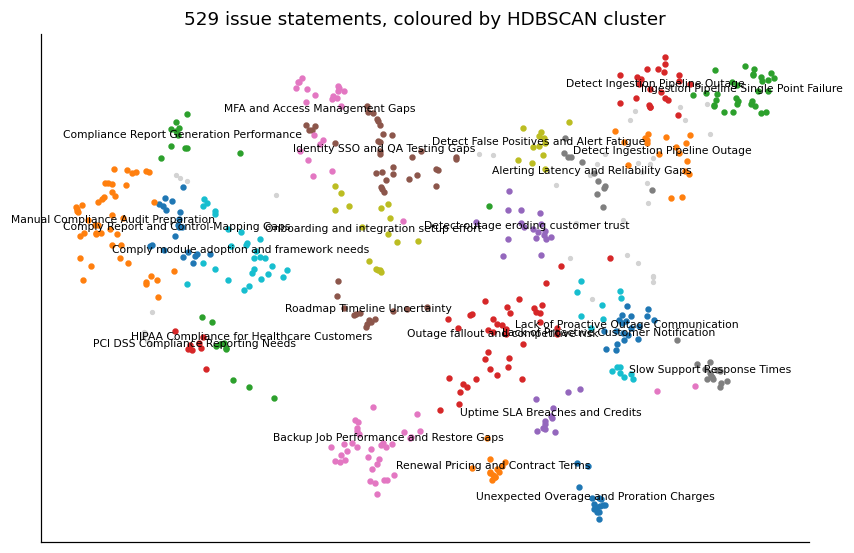

In [13]:
xy = cl.umap_2d(E_iss)
fig, ax = plt.subplots(figsize=(9, 6))
ax.scatter(*xy[iss.cluster == -1].T, s=6, c="lightgrey", label="noise")
for c_ in sorted(set(iss.cluster) - {-1}):
    p = xy[iss.cluster == c_]
    ax.scatter(*p.T, s=10)
    nm = named.set_index("cluster").name.get(c_, "")
    ax.annotate(nm, p.mean(axis=0), fontsize=7, ha="center")
ax.set(xticks=[], yticks=[], title="529 issue statements, coloured by HDBSCAN cluster")
plt.show()

In [14]:
print("Distinct parents suggested by the LLM:", named.suggested_parent.nunique())
print("Outage-related clusters:", named[named.name.str.contains("(?i)outage|ingestion|trust|fallout")].name.tolist())
print("\nSample of noise statements:"); print(iss[iss.cluster == -1].statement.sample(6, random_state=0).to_string(index=False))

Distinct parents suggested by the LLM: 17
Outage-related clusters: ['Outage fallout and competitive risk', 'Detect outage eroding customer trust', 'Lack of Proactive Outage Communication', 'Detect Ingestion Pipeline Outage', 'Ingestion Pipeline Single Point Failure', 'Detect Ingestion Pipeline Outage']

Sample of noise statements:
                      Uncertainty whether events generated during the outage window will be backfilled or lost
            Outage leaves critical OT/SCADA environments without threat monitoring, forcing manual log review.
                Compliance reports surfacing control gaps are driving cross-sell interest in identity products
Remediation changes from a prior incident may have degraded shared cluster resource allocation for other se...
                      PCI DSS report download modal renders incorrectly in Safari due to a cosmetic layout bug
              Workaround of manual log review during outage is unacceptable for an automated detection product


> **Findings:** issue-level clustering is much sharper than call-level — 24 named themes, 7% noise, most rated
> high/medium coherence by the naming step. But three things stop it being a taxonomy on its own:
> 1. **Unstable** — cross-seed ARI 0.55 (min 0.43), 19–25 clusters depending on seed.
> 2. **Splits one story** — the March outage spans 5 clusters; incident communication appears twice.
> 3. **Inconsistent naming** — 17 different parent groups for 24 clusters ("Identity" vs "Identity & Authentication").
>
> **Decision:** clusters are the *discovery* step. A human curates them into a fixed taxonomy, and classification
> uses that fixed list — so labels are stable, comparable over time, and owned by someone.

## 6. Curated 2-level taxonomy

Full merge/split log with reasons: `taxonomy/CURATION.md`. Each level-1 group maps to an owner.

In [15]:
tax = topics.load_taxonomy()
raw_tax = json.loads((Path.cwd().parent / "taxonomy" / "taxonomy.json").read_text())
src = {t["name"]: t.get("source_clusters", []) for ts in raw_tax.values() for t in ts}
cname = named.set_index("cluster").name
tax.assign(from_clusters=tax.l2.map(lambda n: "; ".join(cname.get(c, "?") for c in src[n]) or "— added in curation"))

,l1,l2,definition,from_clusters
0,Reliability & Incidents,Outage root cause & remediation,"Technical cause of a platform outage or degradation and the engineering fixes (failover, circuit breakers,...",Detect Ingestion Pipeline Outage; Ingestion Pipeline Single Point Failure; Detect Ingestion Pipeline Outage
1,Reliability & Incidents,Outage business impact & trust,"Effect of an outage on the customer: lost visibility, audit/regulatory exposure, eroded confidence, escala...",Outage fallout and competitive risk; Detect outage eroding customer trust
2,Reliability & Incidents,Incident communication,How (or whether) customers were notified and kept informed during and after an incident.,Lack of Proactive Customer Notification; Lack of Proactive Outage Communication
3,Reliability & Incidents,SLAs & service credits,"Uptime commitments, SLA breaches, credits and contractual reliability terms.",Uptime SLA Breaches and Credits
4,Product Gaps,Detect alert quality,"Alert latency, missed alerts, false positives and alert fatigue in Detect.",Alerting Latency and Reliability Gaps; Detect False Positives and Alert Fatigue
5,Product Gaps,Integrations & connectors,"SIEM (LogVault), cloud and backup connectors: setup effort, timeouts, data gaps, configuration complexity.",— added in curation
6,Product Gaps,Identity authentication & access,"SSO/SAML, MFA, LDAP/SCIM provisioning, login failures and access management in Identity.",Identity SSO and QA Testing Gaps; MFA and Access Management Gaps
7,Product Gaps,Backup & restore performance,"Protect backup windows, throughput, restore granularity and recovery reliability.",Backup Job Performance and Restore Gaps
8,Product Gaps,Compliance audit preparation,"Using Comply to prepare for audits: evidence collection, manual effort, readiness reviews.",Manual Compliance Audit Preparation
9,Product Gaps,Compliance framework coverage,"Which frameworks Comply supports and how well (SOC 2, HIPAA, PCI DSS, ISO 27001), custom templates, adopti...",HIPAA Compliance for Healthcare Customers; PCI DSS Compliance Reporting Needs; Comply module adoption and ...


> **Decisions:** 24 clusters → 19 themes in 5 groups. Merged duplicates (5 outage clusters → 2 themes; SSO + MFA → 1),
> and **added 3 themes clustering missed**: *Integrations & connectors* (spread across clusters), *Competitive pressure*
> (split from outage fallout because sales needs it independently), *Release quality & regressions*
> (QA gaps and remediation side-effects were buried in other clusters and noise).

## 7. Classify every call into the taxonomy (multi-label + confidence + evidence)

The schema restricts labels to the 19 curated names (a `Literal` type), so Claude cannot invent categories.
Each label carries a confidence and a verbatim quote.

In [16]:
assigned = topics.classify(calls, red, tax)
print(f"{assigned.meeting_id.nunique()} calls · {len(assigned)} labels · quotes grounded {assigned.grounded.mean():.0%}")
print("Labels per call:", assigned.groupby("meeting_id").size().value_counts().sort_index().to_dict())
print("Confidence — primary median", assigned[assigned.is_primary].confidence.median(),
      "· secondary median", assigned[~assigned.is_primary].confidence.median())

100 calls · 382 labels · quotes grounded 100%
Labels per call: {2: 2, 3: 14, 4: 84}
Confidence — primary median 0.92 · secondary median 0.7


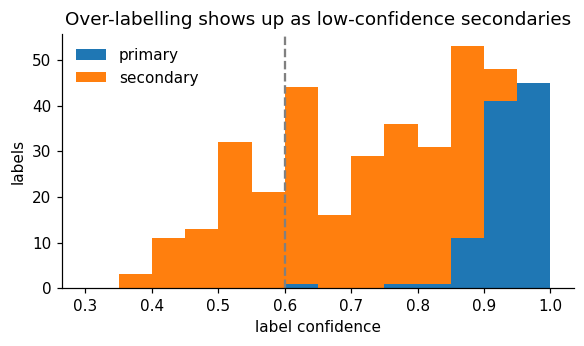

                                                                 title                     theme  confidence                                                                                                                            evidence_quote
Support Case #8811 - Blackridge Investments Custom Compliance Template     Onboarding & adoption        0.35                 we upgraded to Comply v2 — gosh, what was it, like mid-April? — and honestly the on-demand reporting has been phenomenal.
       Support Case #3546 - Meridian Capital SCIM Provisioning Request Integrations & connectors        0.40 Okta actually has a generic API connector that you can configure to hit our user management endpoints, it's not as turnkey as native SCIM
            Support Case #3615 - Nimbus Platform Custom Report Request        Support experience        0.40              What I can do is make sure this case gets properly escalated to our product team with the specific use case you've described
            

In [17]:
fig, ax = plt.subplots(figsize=(6, 3))
ax.hist([assigned[assigned.is_primary].confidence, assigned[~assigned.is_primary].confidence],
        bins=np.arange(0.3, 1.01, 0.05), stacked=True, label=["primary", "secondary"])
ax.axvline(0.6, ls="--", c="grey"); ax.set(xlabel="label confidence", ylabel="labels", title="Over-labelling shows up as low-confidence secondaries")
ax.legend(frameon=False); plt.show()
print(assigned[assigned.confidence < 0.5].sample(4, random_state=1)[["title", "theme", "confidence", "evidence_quote"]].to_string(index=False))

> **Finding:** Claude fills the 4-label cap on 84% of calls. Primary labels are confident (median 0.92); labels under
> ~0.6 are passing mentions (e.g. *Onboarding & adoption* at 0.35 on a call that merely mentions when the customer upgraded).
>
> **Decision:** count a theme for a call only at **confidence ≥ 0.6** (→ 3.0 labels/call). The threshold is checked
> against the hand labels in §8. Next iteration: tighten the prompt ("only themes that take up a meaningful part of the call").

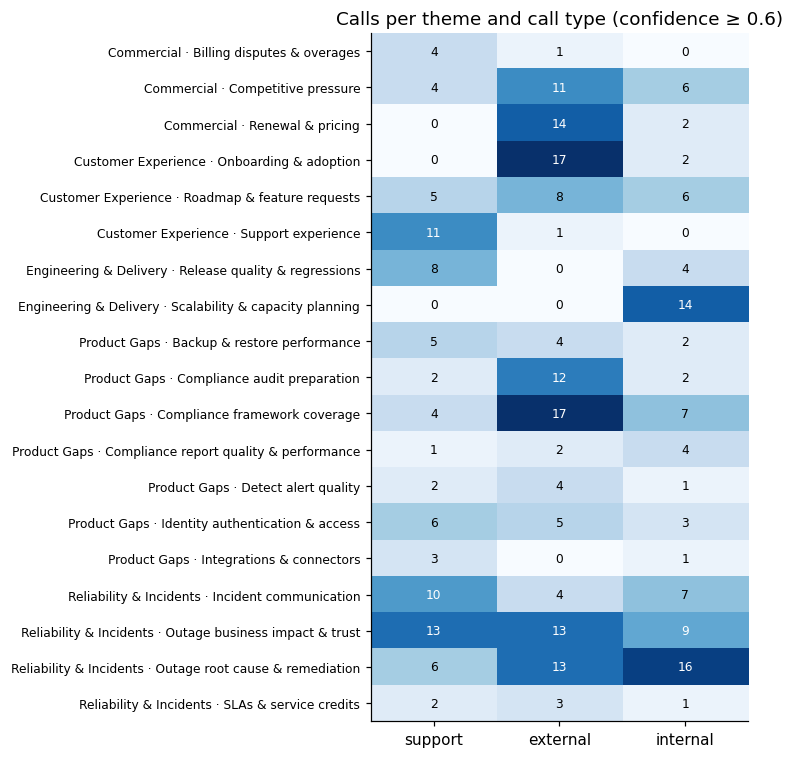

call_type                                                        support  external  internal  total calls  as primary
l1                      theme                                                                                        
Commercial              Billing disputes & overages                    4         1         0            5           4
                        Competitive pressure                           4        11         6           21           6
                        Renewal & pricing                              0        14         2           16          12
Customer Experience     Onboarding & adoption                          0        17         2           19           7
                        Roadmap & feature requests                     5         8         6           19           8
                        Support experience                            11         1         0           12           0
Engineering & Delivery  Release quality & regressions                  8         0         4           12           1
                        Scalability & capacity planning                0         0        14           14           7
Product Gaps            Backup & restore performance                   5         4         2           11           5
                        Compliance audit preparation                   2        12         2           16           6
                        Compliance framework coverage                  4        17         7           28           8
                        Compliance report quality & performance        1         2         4            7           1
                        Detect alert quality                           2         4         1            7           3
                        Identity authentication & access               6         5         3           14           7
                        Integrations & connectors                      3         0         1            4           3
Reliability & Incidents Incident communication                        10         4         7           21           0
                        Outage business impact & trust                13        13         9           35          11
                        Outage root cause & remediation                6        13        16           35          11
                        SLAs & service credits                         2         3         1            6           0

In [18]:
THRESHOLD = 0.6
kept = assigned[(assigned.confidence >= THRESHOLD) | assigned.is_primary]
counts = (kept.pivot_table(index=["l1", "theme"], columns="call_type", values="meeting_id", aggfunc="nunique")
               .reindex(columns=TYPE_ORDER).fillna(0).astype(int))
counts["total calls"] = kept.groupby(["l1", "theme"]).meeting_id.nunique()
counts["as primary"] = kept[kept.is_primary].groupby(["l1", "theme"]).size()
counts = counts.fillna(0).astype(int)

fig, ax = plt.subplots(figsize=(7, 7))
m = counts[TYPE_ORDER].values
ax.imshow(m, cmap="Blues", aspect="auto")
ax.set_xticks(range(3), TYPE_ORDER); ax.set_yticks(range(len(counts)), [f"{a} · {b}" for a, b in counts.index], fontsize=8)
for (i, j), v in np.ndenumerate(m):
    ax.text(j, i, v, ha="center", va="center", fontsize=8, color="white" if v > m.max() / 2 else "black")
ax.set_title(f"Calls per theme and call type (confidence ≥ {THRESHOLD})"); plt.tight_layout(); plt.show()
counts

### Examples per theme

Two calls per theme, preferring calls where it is the primary label, with the quote that supports it.

In [19]:
ex = (kept.sort_values(["is_primary", "confidence"], ascending=False)
          .groupby("theme").head(2)
          .merge(tax[["l2"]], left_on="theme", right_on="l2"))
ex["order"] = ex.theme.map({t: i for i, t in enumerate(tax.l2)})
ex.sort_values(["order", "is_primary"], ascending=[True, False])[["l1", "theme", "title", "call_type", "is_primary", "confidence", "evidence_quote"]].reset_index(drop=True)

,l1,theme,title,call_type,is_primary,confidence,evidence_quote
0,Reliability & Incidents,Outage root cause & remediation,Detect Outage - Remediation Plan Review,internal,True,0.97,"we had a single point of failure in the event ingestion layer, and when that node went down, there was no ..."
1,Reliability & Incidents,Outage root cause & remediation,Detect Outage - Root Cause Analysis,internal,True,0.97,we had a cascading failure in the event ingestion layer. There's essentially a single point of failure in ...
2,Reliability & Incidents,Outage business impact & trust,Aegis / Northstar Pharma - Urgent: Detect Outage Impact,external,True,0.95,"Do you understand the regulatory exposure we have? We're a pharma company, we operate under HIPAA, we have..."
3,Reliability & Incidents,Outage business impact & trust,ESCALATION: Northstar Pharma - Detect Outage Impact on Compliance,support,True,0.95,We are in the middle of a SOC 2 audit cycle. We have to demonstrate continuous monitoring. If there's a ga...
4,Reliability & Incidents,Incident communication,INCIDENT: Detect Pipeline Failure - War Room,internal,False,0.90,Customers would rather have an incomplete honest update than silence.
5,Reliability & Incidents,Incident communication,ESCALATION: Northstar Pharma - Detect Outage Impact on Compliance,support,False,0.88,And nobody called us? Nobody sent an email? Customer 1 found out because she happened to check the dashboa...
6,Reliability & Incidents,SLAs & service credits,Aegis / Quantum Edge - Renewal Concerns,external,False,0.80,"So your current contract has a 99.5% uptime SLA for Detect, and the six-hour outage did breach that."
7,Reliability & Incidents,SLAs & service credits,Detect Outage - Customer Impact Assessment,internal,False,0.80,Their contract has a 99.9% uptime SLA and six hours down is — that's not compliant. We're probably looking...
8,Product Gaps,Detect alert quality,Aegis / Harborview Banking - Threat Detection Tuning,external,True,0.95,The false positive issue is honestly top of mind right now. Our SOC team is getting fatigued — they're see...
9,Product Gaps,Detect alert quality,Support Case #3103 - Silverline Brands Detect False Positives After Patch,support,True,0.95,our on-call person spent the entire morning triaging and every single one of them was a false positive. Ev...


### What the categories say

- **The outage dominates the quarter.** *Outage business impact & trust* and *root cause & remediation* are the two most common themes and appear across **all three call types** — it is a company-wide event, not an engineering one.
- **Some themes are never primary but always present.** *Support experience*, *Incident communication* and *SLAs & service credits* are never a call's main topic, yet show up as secondary themes again and again. They're the "how we handled it" layer that call titles never mention, which is exactly what a topic tool should surface.
- **A curation call to revisit.** *Integrations & connectors*, which I added in curation, holds only 4 calls at the 0.6 threshold — integration problems are mostly being labelled under the product they affect. If the hand labels agree, merge it into the product themes.
- **Ownership is visible.** *Renewal & pricing* lives in external calls, *Release quality* and *Scalability & capacity* in internal and support calls, *Compliance framework coverage* in external calls — each L1 group lands with a different owner.

## 8. Validation

**Automatic:** every evidence quote — extraction and classification — is checked against the transcript.
**Human:** 25 calls chosen *before* any LLM output (stratified by call type × outage period, all 4 incident-flagged
external calls included), labelled blind from the redacted transcripts in `labeling/`.

In [20]:
auto = pd.Series({
    "extraction quotes grounded": issues.grounded.mean(),
    "classification quotes grounded": assigned.grounded.mean(),
    "call-type rule vs LLM agreement": ct.agrees.mean(),
    "calls with exactly one primary": (assigned.groupby("meeting_id").is_primary.sum() == 1).mean(),
}).map("{:.0%}".format)
auto.to_frame("automatic check")

,automatic check
extraction quotes grounded,100%
classification quotes grounded,100%
call-type rule vs LLM agreement,100%
calls with exactly one primary,100%


In [21]:
labels = load_labels()
filled = labels[labels.primary_theme.str.strip() != ""]
if filled.empty:
    print(f"Hand labels pending: 0/{len(labels)} calls labelled in {LABEL_DIR / 'label_sheet.csv'}")
else:
    bad = set(filled.primary_theme) | set(t for ts in filled.other_themes for t in ts)
    bad -= set(tax.l2)
    assert not bad, f"Theme names not in taxonomy: {bad}"
    for thr in (0.0, 0.5, 0.6, 0.7):
        per_call, per_theme = topics.evaluate(filled, assigned[(assigned.confidence >= thr) | assigned.is_primary])
        print(f"threshold {thr}: primary accuracy {per_call.primary_match.mean():.0%} · mean Jaccard {per_call.jaccard.mean():.2f}")
    per_call, per_theme = topics.evaluate(filled, kept)
    if (filled.call_type != "").any():
        ct_h = filled[filled.call_type != ""].merge(calls[["meeting_id", "call_type"]], on="meeting_id", suffixes=("_human", "_rule"))
        print(f"call type: rule matches human on {(ct_h.call_type_human == ct_h.call_type_rule).mean():.0%} of {len(ct_h)}")
    display(per_theme.round(2)); display(per_call[~per_call.primary_match][["title", "human_primary", "model_primary"]])

Hand labels pending: 0/25 calls labelled in /Users/maheshg/PycharmProjects/interview-assignment/labeling/label_sheet.csv


## 9. Outputs and cost

In [22]:
themes_kept = kept.groupby("meeting_id").theme.agg(lambda s: "; ".join(sorted(s)))
primary = assigned[assigned.is_primary].set_index("meeting_id")[["theme", "l1", "confidence"]] \
            .rename(columns={"theme": "primary_theme", "l1": "primary_group", "confidence": "primary_confidence"})
out = (calls[["meeting_id", "start", "title", "call_type", "account"]]
       .merge(ct[["meeting_id", "llm_incident"]], on="meeting_id")
       .merge(calls_x[["meeting_id", "primary_purpose", "churn_risk", "resolution"]], on="meeting_id")
       .join(primary, on="meeting_id").join(themes_kept.rename("themes"), on="meeting_id"))
out.to_csv(REPORTS / "call_topics.csv", index=False)
iss.merge(named[["cluster", "name"]].rename(columns={"name": "cluster_name"}), how="left").to_csv(REPORTS / "issues.csv", index=False)
assigned.to_csv(REPORTS / "call_theme_labels.csv", index=False)
print("Wrote reports/call_topics.csv, reports/issues.csv, reports/call_theme_labels.csv")
out.head()

Wrote reports/call_topics.csv, reports/issues.csv, reports/call_theme_labels.csv


,meeting_id,start,title,call_type,account,llm_incident,primary_purpose,churn_risk,resolution,primary_theme,primary_group,primary_confidence,themes
0,01KQ03B0303900521BB089CA,2026-03-16 09:30:00+00:00,Detect Outage - Remediation Plan Review,internal,None,True,Align on Detect outage remediation plan,not_applicable,not_applicable,Outage root cause & remediation,Reliability & Incidents,0.97,Incident communication; Outage business impact & trust; Outage root cause & remediation
1,01KQ0C1280EDA4E70AAD7C35,2026-02-06 09:15:00+00:00,Support Case #9279 - Summit Trust Billing Inquiry,support,summittrust.com,False,Dispute Identity seat overage on invoice,low,partially_resolved,Billing disputes & overages,Commercial,0.97,Billing disputes & overages
2,01KQ0CAE7F064EC93F0540CA,2026-02-16 10:00:00+00:00,Weekly Engineering Standup,internal,None,False,Weekly engineering status and timeline check,not_applicable,not_applicable,Scalability & capacity planning,Engineering & Delivery,0.85,Outage root cause & remediation; Scalability & capacity planning
3,01KQ0DFE299AC7A74E8022CA,2026-04-26 13:30:00+00:00,Aegis / Redwood Clinical - ISO 27001 Preparation,external,redwoodclinical.com,False,ISO 27001 preparation and Comply v2 onboarding,low,not_applicable,Compliance audit preparation,Product Gaps,0.90,Compliance audit preparation; Compliance framework coverage; Onboarding & adoption
4,01KQ0F8AFF3DA34FD4580008,2026-04-11 14:15:00+00:00,Aegis / Cobalt Software - Q2 Planning,external,cobaltsoftware.com,True,Renewal planning and account health review,medium,partially_resolved,Renewal & pricing,Commercial,0.85,Competitive pressure; Outage business impact & trust; Outage root cause & remediation; Renewal & pricing


In [23]:
# Cost of the one paid run, read back from the cache (this notebook itself made no API calls if `calls` is 0 below)
print("This run:", llm.usage_totals)
print("Paid run (Oct 2026, measured from response usage): call type + extraction $5.39 · cluster naming $0.19 · "
      "classification $2.84 · smoke test $0.17 → ≈ $8.60 for 100 calls (≈ $0.09/call)")

This run: {'calls': 0, 'cached': 324, 'input_tokens': 0, 'output_tokens': 0, 'refusals': 0}
Paid run (Oct 2026, measured from response usage): call type + extraction $5.39 · cluster naming $0.19 · classification $2.84 · smoke test $0.17 → ≈ $8.60 for 100 calls (≈ $0.09/call)


## Summary — what I found and what I decided

| Finding | Decision |
|---|---|
| Rules and LLM agree on call type for 100/100 calls | Keep rules (free, deterministic); LLM is the audit, not the classifier |
| Title rule finds 15 incident calls, LLM finds 37 | Use LLM incident flag; outage reach is ~2.5× what titles show |
| Whole-call clustering: weak separation, one label per call | Extract issues first, cluster issues instead of calls |
| 529 extracted issues, 100% of quotes grounded | Trust extraction as the base layer for themes and insights |
| Issue clusters: sharp but unstable (ARI 0.55) and split stories | Use clusters for discovery only; human curates a fixed taxonomy |
| 24 clusters → 19 themes, 3 themes added that clustering missed | Fixed 2-level taxonomy with an owner per group |
| Classifier fills the 4-label cap; low-confidence labels are passing mentions | Count themes at confidence ≥ 0.6; validate threshold on hand labels |
| Outage themes are the most common and span all call types | Headline for the deck — and the anchor for sentiment trends (notebook 03) |

**Scaling note:** at ≈ $0.09/call this runs on every new call; the taxonomy only changes when a periodic re-clustering
of new issue statements surfaces a theme the fixed list doesn't cover (watch the share of low-confidence / noise issues).